In [1]:
from IPython.display import display, Image
from pprint import pprint
from itertools import chain, product

import symmetry
from ginv import *
sympy.init_printing()

**1. Исходное уравнение:**

Уравнение Бюргерса нелинейно и моделирует течение жидкости и ударные волны:
$$
u_t + u u_x = u_{xx}
$$

Если искать его классические точечные симметрии Ли, мы найдём некоторое их количество (связанные с трансляциями, растяжениями и преобразованием Галилея). Но мы используем его, чтобы проиллюстрировать технику.

In [2]:
eps, t, x = sympy.symbols('ε, t, x', real=True)
U = sympy.Function('u')(eps, t, x)

u, ut, ux = sympy.symbols('u, u_t, u_x', real=True)
F = sympy.Function('f')(t, x, u, ut, ux)

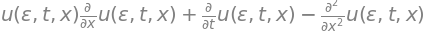

In [3]:
eq1 = U.diff(t) + U*U.diff(x) - U.diff(x, 2)
eq1

In [4]:
lmNF, eqNF = [U.diff(x, 2)], [eq1]

In [5]:
symmetry.compact(eq1)

In [6]:
symmetry.compact(eq1.diff(eps))

In [7]:
symmetry.init({U: F}, (t, x))

In [8]:
print(f"$$ u_{{xx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2), lmNF, eqNF)))}$$")
print(f"$$ u_{{txx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2, t), lmNF, eqNF)))}$$")
print(f"$$ u_{{xxx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2, x), lmNF, eqNF)))}$$")

$$ u_{xx} = u u_{x} + u_{t}$$
$$ u_{txx} = u u_{tx} + u_{tt} + u_{t} u_{x}$$
$$ u_{xxx} = u^{2} u_{x} + u u_{t} + u_{tx} + u_{x}^{2}$$


$$ u_{xx} = u u_{x} + u_{t}$$
$$ u_{txx} = u u_{tx} + u_{tt} + u_{t} u_{x}$$
$$ u_{xxx} = u^{2} u_{x} + u u_{t} + u_{tx} + u_{x}^{2}$$

In [9]:
def Dt(a):
    return a.diff(t) + a.diff(u)*U.diff(t)\
        + a.diff(ut)*U.diff(t, t) + a.diff(ux)*U.diff(x, t)
def Dx(a):
    return a.diff(x) + a.diff(u)*U.diff(x)\
        + a.diff(ut)*U.diff(t, x) + a.diff(ux)*U.diff(x, x)

In [10]:
toD = {
    t: Dt,\
    x: Dx,\
}

In [11]:
eq3 = symmetry.totalD(eq1.diff(eps), eps, toD).expand() 
symmetry.compact(eq3)

In [12]:
eq5 = symmetry.NF(eq3, lmNF, eqNF)
symmetry.compact(eq5)

In [13]:
toU = {
    U.diff(t): ut,\
    U.diff(x): ux,\
    U: u,\
}

In [14]:
eq7 = symmetry.lstD(eq5, toU).expand()

In [15]:
symmetry.compact(eq7)

In [16]:
print(print(sympy.latex([symmetry.compact(df) for df in symmetry.sym_DF])))
[symmetry.compact(df) for df in symmetry.sym_DF]

\left[ u_{tx}\right]
None


In [17]:
eq9 = symmetry.to_eqs([eq7], symmetry.sym_DF)
for eq in eq9:
    display(symmetry.compact(eq))

In [18]:
var = 't, x, u, u_t, u_x'.split(', ')
Monom.cmp = Monom.TOPgrevlex
v1, f1 = PolyDiff.init(var, ['f'])
df = PolyDiff.df
diff2poly = PolyDiff.diff2poly
LRT = Janet()
res = ginvBlockLow([diff2poly(eq) for eq in eq9], \
LRT, level=1)


prolong 0, Q 2
df(f, u_t, 2)
prolong 0, Q 2
df(f, x, u_t)
prolong 2, Q 2
df(f, x, 2)
prolong 2, Q -1
df(f, u_t, u_x)
prolong 2, Q 3
df(f, u, u_t)
prolong 2, Q 3
df(f, t, u_t)
prolong 2, Q -1
df(f, u_x, 2)
prolong 2, Q 3
df(f, u, u_x, 2)
prolong 3, Q 3
df(f, x, u_x, 2)
prolong 3, Q 3
df(f, u, u_x)
prolong 2, Q 3
df(f, t, u_x, 2)
prolong 3, Q 3
df(f, x, u, u_x)
prolong 2, Q 3
df(f, t, u, u_x)
prolong 2, Q 3
df(f, x, u, u_t)
prolong 3, Q 3
df(f, t, u, u_t)
prolong 3, Q 3
df(f, x, u)
prolong 2, Q 3
df(f, u, 2)
prolong 2, Q 3
df(f, x, u_x)
prolong 2, Q 3
df(f, t, u_x)
prolong 2, Q 3
df(f, t, u)
prolong 0, Q 3
df(f, t)
prolong 0, Q 2
prolong 0, Q -1


In [19]:
print(f"time: {res[0]:.2f} sec")
print(f"  HP: {LRT.HP()}")
LRT.isInvolutive()

time: 0.53 sec
  HP: 5


True

In [21]:
for wrap in LRT.GB():
    print(wrap.poly)

df(f, u_x, 2)
df(f, u_t, u_x)
df(f, u_t, 2)
df(f, u, u_x)
df(f, u, u_t)
df(f, u, 2)
df(f, x, u_x)*(-1) + df(f, u)
df(f, x, u_t)
df(f, x, u)
df(f, x, 2)
df(f, t)*(-1) + df(f, x)*(-u) + df(f, u)*(2*u*u_x + 2*u_t) + df(f, u_t)*(u_t*u_x) + df(f, u_x)*(u_x**2) + df(f)*(-u_x)


In [22]:
A, B, C, D = [sympy.Function(i)(t, x) for i in "A, B, C, D".split(', ')]
F1 = [A*ut + B*ux + C*u + D]
eqs1 = []
for wrap in LRT.GB():
    eqs1.append(sum(F1[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs1:
    if eq: display(symmetry.compact(eq))

In [23]:
A, B, C, D = [sympy.Function(i) for i in "A, B, C, D".split(', ')]
F2 = [A(t)*ut + (C(t)*x + B(t))*ux + C(t)*u + D(t, x)]
eqs2 = []
for wrap in LRT.GB():
    eqs2.append(sum(F2[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs2:
    if eq: display(symmetry.compact(eq))

In [24]:
A, B, C, D0, D1 = [sympy.Function(i) for i in "A, B, C, D0, D1".split(', ')]
F3 = [A(t)*ut + (0*C(t)*x + B(t))*ux + C(t)*u + D1(t)*x + D0(t)]
eqs3 = []
for wrap in LRT.GB():
    eqs3.append(sum(F3[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs3:
    if eq:
        display(symmetry.compact(eq))

In [25]:
eqs4 = symmetry.to_eqs(eqs3, [ut, ux, u, x])
for eq in eqs4:
    if eq: display(symmetry.compact(eq))

In [26]:
A, B, C, D0, D1 = sympy.symbols('A, B, C, D0, D1', real=True)
F4 = [(-D1*t**2 + 2*C*t + A)*ut + ((-D1*t + C)*x + (-D0*t + B))*ux 
      + (-D1*t + C)*u + D1*x + D0]
eqs5 = []
for wrap in LRT.GB():
    eqs5.append(sum(F4[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs5:
    if eq: display(symmetry.compact(eq))

In [27]:
s = F4[0].expand()
symm = [s.coeff(i) for i in (A, B, C, D0, D1)]
symm

In [28]:
eq7.subs(F, s).doit().simplify()

### Классические симметрии (точечные симметрии)

Точечные симметрии — это такие преобразования переменных $t, x, u$, которые переводят любое решение уравнения в другое решение того же уравнения. Для их нахождения используется стандартный алгоритм Ли.

**Найденные симметрии для уравнения Бюргерса:**

1.  **Сдвиг по времени** (инвариантность относительно однородности времени):
    *   Преобразование: $ t \to t + \varepsilon, \quad x \to x, \quad u \to u $
    *   Оператор: $ X_1 = \frac{\partial}{\partial t} $
    *   Физический смысл: уравнение не меняется, если начать отсчет времени с другого момента.

2.  **Сдвиг по пространству** (инвариантность относительно однородности пространства):
    *   Преобразование: $ t \to t, \quad x \to x + \varepsilon, \quad u \to u $
    *   Оператор: $ X_2 = \frac{\partial}{\partial x} $
    *   Физический смысл: уравнение не меняется, если сместить начало координат.

3.  **Масштабные преобразования (подобия)**:
    *   Преобразование: $ t \to e^{\varepsilon} t, \quad x \to e^{\varepsilon/2} x, \quad u \to e^{-\varepsilon/2} u $
    *   Оператор: $ X_3 = t \frac{\partial}{\partial t} + \frac{1}{2} x \frac{\partial}{\partial x} - \frac{1}{2} u \frac{\partial}{\partial u} $
    *   Физический смысл: существует связь между изменением масштабов времени, пространства и амплитуды скорости.

**2. Введение потенциалов (Преобразование Хопфа-Коула)**

Запишем уравнение Бюргерса как условие совместности. Предположим, что существует потенциал $ w $, такой что:
$$
w_x = u
$$
$$
w_t = u_x - \frac{1}{2}u^2
$$

Проверим совместность: $ \frac{\partial}{\partial t}(w_x) = \frac{\partial}{\partial x}(w_t) $.
*   Левая часть: $ u_t $
*   Правая часть: $ u_{xx} - u u_x $

Приравнивая, получаем: $ u_t = u_{xx} - u u_x $, что в точности является уравнением Бюргерса. Таким образом, система потенциалов эквивалентна исходному уравнению.

In [46]:
eps, t, x = sympy.symbols('ε, t, x', real=True)
U = sympy.Function('u')(eps, t, x)
W = sympy.Function('w')(eps, t, x)

w, u, ut, ux = sympy.symbols(r'w, u, u_t, u_x', real=True)
F = sympy.Function('f')(t, x, w, u, ut, ux)
H = sympy.Function('h')(t, x, w, u, ut, ux)

In [47]:
eq0 = W.diff(x) - U
eq0

In [48]:
eq1 = W.diff(t) - U.diff(x) + U**2/2
eq1

In [49]:
# TODO
lmNF, eqNF = [W.diff(x), W.diff(t), U.diff(x, 2)], [eq0, eq1, eq0.diff(t) - eq1.diff(x)]

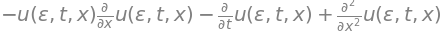

In [50]:
eq0.diff(t) - eq1.diff(x)

In [51]:
symmetry.compact(eq0)

In [52]:
symmetry.compact(eq0.diff(eps))

In [53]:
symmetry.compact(eq1)

In [54]:
symmetry.compact(eq1.diff(eps))

In [55]:
symmetry.init({U: F, W: H}, (t, x))

In [56]:
print(f"$$ w_t = {sympy.latex(symmetry.compact(symmetry.NF(W.diff(t), lmNF, eqNF)))}$$")
print(f"$$ w_x = {sympy.latex(symmetry.compact(symmetry.NF(W.diff(x), lmNF, eqNF)))}$$")
print(f"$$ u_{{xx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2), lmNF, eqNF)))}$$")
print(f"$$ u_{{txx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2, t), lmNF, eqNF)))}$$")
print(f"$$ u_{{xxx}} = {sympy.latex(symmetry.compact(symmetry.NF(U.diff(x, 2, x), lmNF, eqNF)))}$$")

$$ w_t = - \frac{u^{2}}{2} + u_{x}$$
$$ w_x = u$$
$$ u_{xx} = u u_{x} + u_{t}$$
$$ u_{txx} = u u_{tx} + u_{tt} + u_{t} u_{x}$$
$$ u_{xxx} = u^{2} u_{x} + u u_{t} + u_{tx} + u_{x}^{2}$$


$$ w_t = - \frac{u^{2}}{2} + u_{x}$$
$$ w_x = u$$
$$ u_{xx} = u u_{x} + u_{t}$$
$$ u_{txx} = u u_{tx} + u_{tt} + u_{t} u_{x}$$
$$ u_{xxx} = u^{2} u_{x} + u u_{t} + u_{tx} + u_{x}^{2}$$

In [57]:
def Dt(a):
    return a.diff(t) + a.diff(u)*U.diff(t) + a.diff(ut)*U.diff(t, t)\
        + a.diff(ux)*U.diff(x, t) + a.diff(w)*W.diff(t)
def Dx(a):
    return a.diff(x) + a.diff(u)*U.diff(x) + a.diff(ut)*U.diff(t, x)\
        + a.diff(ux)*U.diff(x, x) + a.diff(w)*W.diff(x)

In [58]:
toD = {
    t: Dt,\
    x: Dx,\
}

In [59]:
eq2 = symmetry.totalD(eq0.diff(eps), eps, toD).expand() 
symmetry.compact(eq2)

In [60]:
eq3 = symmetry.totalD(eq1.diff(eps), eps, toD).expand() 
symmetry.compact(eq3)

In [61]:
eq4 = symmetry.NF(eq2, lmNF, eqNF)
symmetry.compact(eq4)

In [62]:
eq5 = symmetry.NF(eq3, lmNF, eqNF)
symmetry.compact(eq5)

In [63]:
toU = {
    U.diff(t): ut,\
    U.diff(x): ux,\
    U: u,\
    W: w,\
}

In [64]:
eq6 = symmetry.lstD(eq4, toU).expand()
eq7 = symmetry.lstD(eq5, toU).expand()

In [65]:
symmetry.compact(eq6)

In [66]:
symmetry.compact(eq7)

In [67]:
print(print(sympy.latex([symmetry.compact(df) for df in symmetry.sym_DF])))
[symmetry.compact(df) for df in symmetry.sym_DF]

\left[ u_{tt}, \  u_{tx}\right]
None


In [68]:
eq8 = symmetry.to_eqs([eq6], symmetry.sym_DF)
for eq in eq8:
    display(symmetry.compact(eq))

In [69]:
eq9 = symmetry.to_eqs([eq7], symmetry.sym_DF)
for eq in eq9:
    display(symmetry.compact(eq))

In [70]:
var = 't, x, w, u, u_t, u_x'.split(', ')
Monom.cmp = Monom.POTgrevlex
# Monom.cmp = Monom.TOPgrevlex
v1, f1 = PolyDiff.init(var, ['h', 'f'])
diff2poly = PolyDiff.diff2poly
LRT = Forest(Janet)
res = ginvMin([diff2poly(eq) for eq in eq8 + eq9], \
LRT, level=1)

prolong h*u_x
df(h, u_x)
prolong h*u_t
df(h, u_t)
prolong h*u_t
df(h, x)
prolong h*t
df(h, t)
prolongAll
df(f, u_t, 2)
prolong f*u_t**2
df(h, u)
prolong h*u
df(f, x, u_t)
prolong h*w
df(f, u_t, u_x)
prolong h*w
df(f, u, u_t)
prolong h*w
df(f, w, u_t)
prolong h*w
df(h, w)
prolong h*w
df(f, x, 2)
prolongAll
df(f, u_x, 2)
prolong f*u_x**2
df(f, t, u_t)
prolong f*x*u_x**2
df(f, u, u_x, 2)
prolong f*w*u_x**2
df(f, w, u_x, 2)
prolong f*x*u_x**2
df(f, x, u_x, 2)
prolong f*x*u_x**2
df(f, u, u_x)
prolong f*u*u_x**2
df(f, x, u, u_x)
prolong f*x*u*u_x
df(f, x, u)
prolong f*x*u
df(f, t, u_x, 2)
prolong f*t*u_x**2
df(f, w, u, u_x)
prolong f*w*u*u_x
df(f, u, 2)
prolong f*t*x*u_x
df(f, t, u, u_x)
prolong f*t*x*u_x
df(f, t, x, u_x)
prolongAll
df(f, w, u)
prolong f*w*u*u_x
df(f, w, u_x)
prolong f*w*u_x
df(f, x, w, u_x)
prolong f*x*w*u_x
df(f, t, u, u_t)
prolong f*t*u*u_t
df(f, t, w, u_x)
prolong f*t*x*u_t
df(f, x, w, u_t)
prolong f*t*w*u_t
df(f, t, w, u_t)
prolong f*t*x*u_t
df(f, t, x, u_t)
prolong f*t

In [71]:
print(f"time: {res[0]:.2f} sec")
print(f"HP: {LRT.HP()}")
LRT.isInvolutive()

time: 5.78 sec
HP: 2s + 8


True

In [72]:
print("""Реши набор дифференциальных уравнений. 
df означает производную и каждое уравнение начинается с новой строки.
t, x, w, u, u_t, u_x простые переменные""")
print()
for wrap in LRT.GB():
    if wrap.lm.position() == 1:
        print(wrap.poly)

Реши набор дифференциальных уравнений. 
df означает производную и каждое уравнение начинается с новой строки.
t, x, w, u, u_t, u_x простые переменные

df(f, u_x, 2)
df(f, u_t, u_x)
df(f, u_t, 2)
df(f, u, u_x)
df(f, u, u_t)
df(f, u, 2)
df(f, w, u_x)
df(f, w, u_t)
df(f, w, u)*(2) + df(f, x, u_x) + df(f, u)*(-1)
df(f, w, 2)*(2) + df(f, w)*(-1)
df(f, x, u_t)
df(f, x, u)*(2) + df(f, x, u_x)*(-u) + df(f, w)*(-2) + df(f, u)*(u)
df(f, x, w)*(6) + df(f, t, u)*(-2) + df(f, x, u_x)*(-u**2/2 + 2*u_x) + df(f, x)*(-2) + df(f, w)*(-u) + df(f, u)*(u**2/2)
df(f, x, 2)*(-3) + df(f, t, u)*(-2*u) + df(f, x, u_x)*(-u**3/2 - 4*u*u_x - 6*u_t) + df(f, t)*(3) + df(f, x)*(u) + df(f, w)*(-u**2 - 6*u_x) + df(f, u)*(u**3/2) + df(f, u_t)*(-3*u_t*u_x) + df(f, u_x)*(-3*u_x**2) + df(f)*(3*u_x)
df(f, t, u_x)*(-1) + df(f, x, u_x)*(u) + df(f, w)*(2) + df(f, u_t)*(u_t) + df(f, u_x)*(u_x) + df(f)*(-1)
df(f, t, u_t)*(-1) + df(f, x, u_x)*(2)
df(f, t, w)*(12) + df(f, t, u)*(4*u) + df(f, x, u_x)*(u**3 + 8*u*u_x + 12*u_t) + df(

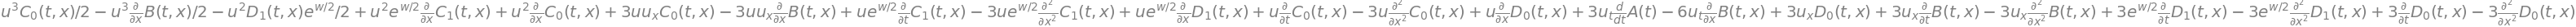

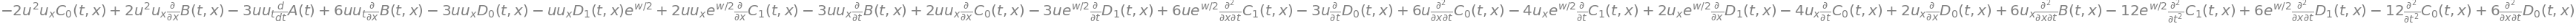

In [73]:
A, B, C1, C0, D1, D0 = [sympy.Function(i)\
    for i in "A, B, C1, C0, D1, D0".split(', ')]
F1 = [0,\
      A(t)*ut + B(t, x)*ux + (sympy.exp(w/2)*C1(t, x) + C0(t, x))*u\
          + sympy.exp(w/2)*D1(t, x) + D0(t, x)]
eqs1 = []
for wrap in LRT.GB():
    if wrap.lm.position() == 1:
        eqs1.append(sum(F1[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs1:
    if eq: display(eq)

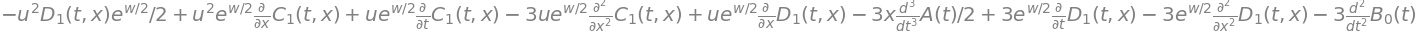

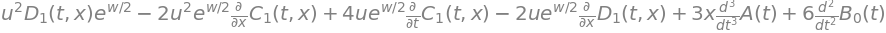

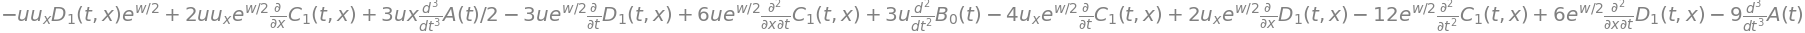

In [74]:
A, B1, B0, C, D = [sympy.Function(i)\
    for i in "A, B1, B0, C, D".split(', ')]
F2 = [0,\
      A(t)*ut + (A(t).diff(t)/2*x + B0(t))*ux + (sympy.exp(w/2)*C1(t, x) + A(t).diff(t)/2)*u\
          + sympy.exp(w/2)*D1(t, x) - (A(t).diff(t)/2*x + B0(t)).diff(t)]
eqs2 = []
for wrap in LRT.GB():
    if wrap.lm.position() == 1:
        eqs2.append(sum(F2[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs2:
    if eq: display(eq)

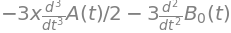

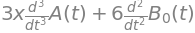

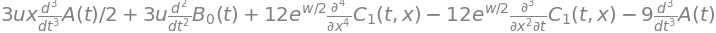

In [75]:
A, B1, B0, C, D = [sympy.Function(i)\
    for i in "A, B1, B0, C, D".split(', ')]
F3 = [0,\
      A(t)*ut + (A(t).diff(t)/2*x + B0(t))*ux + (sympy.exp(w/2)*C1(t, x) + A(t).diff(t)/2)*u\
          + sympy.exp(w/2)*2*C1(t, x).diff(x) - (A(t).diff(t)/2*x + B0(t)).diff(t)]
eqs3 = []
for wrap in LRT.GB():
    if wrap.lm.position() == 1:
        eqs3.append(sum(F3[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs3:
    if eq: display(eq.subs({C1(t, x).diff(t): C1(t, x).diff(x, 2)}))

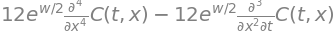

In [76]:
C = sympy.Function("C")(t, x)
A0, A1, A2, B1, B0 = sympy.symbols('A0, A1, A2, B1, B0', real=True)
F4 = [0,\
      (A0 + A1*t + A2*t**2)*ut + ((A1 + 2*A2*t)/2*x + B0 + B1*t)*ux + (sympy.exp(w/2)*C + (A1 + 2*A2*t)/2)*u\
          + sympy.exp(w/2)*2*C.diff(x) - (2*A2/2*x + B1)]
eqs4 = []
for wrap in LRT.GB():
    if wrap.lm.position() == 1:
        eqs4.append(sum(F4[m.position()].diff(*((v, d) for v, d in zip(v1, m)))*c\
                    if m.position() >=0 else c for m, c in wrap.poly).expand())
for eq in eqs4:
    if eq: display(eq.subs({C.diff(t): C.diff(x, 2)}))

In [77]:
s = F4[1].expand()
symm = [s.coeff(i) for i in (A0, A1, A2, B1, B0)]
for i in (A0, A1, A2, B1, B0):
    s = s.coeff(i, 0)
symm.append(s.factor())
symm

**3. Поиск симметрий в расширенной системе**

Теперь ищем симметрии Ли для **системы**:
$$
\begin{cases}
w_x = u \\
w_t = u_x - \frac{1}{2}u^2
\end{cases}
$$

Инфинитезимальный оператор симметрии ищется в виде:
$$
X = \xi(x, t, u, w) \frac{\partial}{\partial x} + \tau(x, t, u, w) \frac{\partial}{\partial t} + \phi(x, t, u, w) \frac{\partial}{\partial u} + \psi(x, t, u, w) \frac{\partial}{\partial w}
$$

Продолжив этот оператор и потребовав инвариантности обоих уравнений системы, можно найти её симметрии. Среди них окажутся не только симметрии исходного уравнения Бюргерса, но и **новые**, которые зависят от потенциала $ w $.

**Пример новой симметрии:**
Можно найти, что одним из операторов симметрии является:
$$
X = e^{-w/2} \left( \frac{\partial}{\partial u} - \frac{u}{2} \frac{\partial}{\partial w} \right)
$$
Это — потенциальная симметрия. Она явно зависит от $ w $, и её нельзя свести к симметрии в терминах только $ x, t, u $.

**4. Использование симметрии и связь с линейностью**

Хотя в данном случае мы нашли потенциальную симметрию, знаменитое преобразование Хопфа-Коула идет дальше. Оно вводит новый потенциал $ w $ таким образом, что система становится линейной.

Положим $ u = -2 \frac{w_x}{w} $. Подставив это в уравнение Бюргерса, получим **линейное уравнение теплопроводности**:
$$
w_t = w_{xx}
$$

Это частный случай проявления потенциальной симметрии. Переход к потенциалу $ w $ раскрыл огромную группу симметрий (симметрии уравнения теплопроводности), которые были скрыты для нелинейного уравнения Бюргерса.